# Template Model

## Cara memakai notebook ini

Notebook ini sudah menyiapkan **data** dan **penilaian** untukmu. Tugasmu hanya satu: **mengisi modelnya**.

1. **Salin dulu** file ini, jangan edit aslinya. Beri nama sesuai modelmu, misalnya `01_linear_regression.ipynb`, `02_random_forest.ipynb`, atau `03_xgboost.ipynb`.
2. Cari sel bertanda **`# === ISI BAGIAN INI ===`**. Hanya sel itu yang boleh kamu ubah.
3. Di sel itu, ganti `NAMA_MODEL` dengan nama modelmu, lalu hapus tanda `#` di depan **satu** baris contoh model yang sesuai.
4. Jalankan semua sel dari atas: menu **Run → Run All Cells** (atau *Restart & Run All*).
5. Lihat tabel di bagian paling bawah. Modelmu harus mengalahkan baris `baseline_lag1`.

## Aturan

- **Jangan ubah sel bertanda `# === JANGAN DIUBAH ===`.** Sel itu menjamin ketiga model memakai data dan cara penilaian yang sama. Kalau diubah, hasilmu tidak bisa dibandingkan dengan milik anggota lain.
- **Jangan pernah memakai `X_test` / `y_test` untuk memilih pengaturan model.** Data 2025 hanya untuk penilaian akhir. Untuk mencoba-coba pengaturan, pakai `lipatan_waktu()` (lihat bagian *Opsional* di bawah).
- Setiap model otomatis dilatih **4 kali**: 2 skenario (`dengan_lag`, `tanpa_lag`) × 2 versi target (`asli`, `log`). Kamu tidak perlu menulis perulangannya.
- Hasil tersimpan otomatis di `hasil/evaluasi.csv`. Selama `NAMA_MODEL` belum diganti, hasil **tidak** disimpan.

## Kalau muncul error

Baca baris **terakhir** pesan error. Sebagian besar sudah ditulis dalam Bahasa Indonesia oleh `fondasi.py` dan menjelaskan apa yang salah. Kalau masih bingung, kirim pesan error lengkapnya ke tim.

Aturan lengkap ada di `docs/STANDAR_PENGERJAAN.md`.

In [1]:
# === JANGAN DIUBAH ===
import sys
from pathlib import Path

# Cari folder akar proyek (yang berisi folder src/), lalu daftarkan src/
AKAR = Path.cwd()
while not (AKAR / "src" / "fondasi.py").exists():
    AKAR = AKAR.parent
sys.path.insert(0, str(AKAR / "src"))

import pandas as pd
from fondasi import (muat_data, evaluasi, info_baris, lipatan_waktu,
                     ke_log, dari_log, SKENARIO, FILE_EVALUASI, RANDOM_STATE)

DATA = {}
for skenario in SKENARIO:
    for jalur in (None, "SNBP", "SNBT"):
        DATA[(skenario, jalur)] = muat_data(skenario, jalur, verbose=False)

pd.DataFrame(
    [(sk, jl or "gabungan", len(d[0]), len(d[1]), d[0].shape[1]) for (sk, jl), d in DATA.items()],
    columns=["skenario", "jalur", "baris_latih", "baris_uji", "jumlah_fitur"])

,skenario,jalur,baris_latih,baris_uji,jumlah_fitur
0,dengan_lag,gabungan,23445,9416,72
1,dengan_lag,SNBP,11729,4707,70
2,dengan_lag,SNBT,11716,4709,70
3,tanpa_lag,gabungan,32959,9799,70
4,tanpa_lag,SNBP,16480,4890,68
5,tanpa_lag,SNBT,16479,4909,68


In [2]:
# === ISI BAGIAN INI ===

# 1. Nama modelmu (huruf kecil, pakai garis bawah). Contoh: "random_forest"
NAMA_MODEL = "random_forest"

# 2. Jalur yang dipakai. None = gabungan SNBP+SNBT (jalur jadi fitur).
JALUR_DIPAKAI = [None]

# 3. Model. PARAMETER_RF berisi pengaturan bawaan dari docs/panduan/shiddiq.md;
#    sel penyetelan di bawah menggantinya dengan pengaturan terpilih lewat
#    validasi berbasis waktu (data latih saja). n_estimators dikunci 300.
from sklearn.ensemble import RandomForestRegressor

PARAMETER_RF = {"max_depth": None, "min_samples_leaf": 1, "max_features": 1.0}

def buat_model():
    return RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **PARAMETER_RF,
    )

### Opsional · Menyetel pengaturan model (hyperparameter)

Kalau ingin mencari pengaturan terbaik, **selalu** pakai `cv=lipatan_waktu(X_train)`, jangan `cv=5`. `cv=5` mengacak data sehingga model belajar dari masa depan dan skornya terlalu bagus. Contoh (salin ke sel baru di atas sel *JANGAN DIUBAH* berikutnya):

```python
from sklearn.model_selection import GridSearchCV
X_train, X_test, y_train, y_test = DATA[("dengan_lag", None)]
cari = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={"n_estimators": [200, 400], "max_depth": [None, 20]},
    cv=lipatan_waktu(X_train), scoring="neg_mean_absolute_error")
cari.fit(X_train, y_train)
print(cari.best_params_)   # lalu pakai angka ini di buat_model()
```

### Penyetelan hyperparameter Random Forest

**Aturan yang ditetapkan sebelum melihat hasil:**

- Hanya data latih 2021–2024 dan `lipatan_waktu()` (K-18). `X_test`/`y_test` tidak disentuh di sel ini.
- Kandidat: pengaturan bawaan + kombinasi acak (24 sampel, `random_state=42`; satu sampel kebetulan sama dengan bawaan dan dilewati, jadi total 24 kandidat) dari `max_depth` {None, 10, 20, 30}, `min_samples_leaf` {1, 2, 5, 10}, `max_features` {1.0, 0.5, 0.33, "sqrt"}. `n_estimators` tidak disetel: 100 pohon dipakai saat pencarian (agar terjangkau), model akhir 300 pohon.
- Setiap kandidat dinilai pada **semua 4 kombinasi** (dengan/tanpa lag × target asli/log), jalur gabungan. Skor = rata-rata MAE (jumlah orang) di seluruh lipatan; untuk target log prediksi dikembalikan dengan `dari_log()` sebelum MAE dihitung.
- Pengaturan terpilih = **rata-rata peringkat MAE terkecil** di keempat kombinasi, satu konfigurasi bersama (karena `buat_model()` dipakai oleh semua kombinasi). Bila seri, dipilih MAE rata-rata terkecil. Pengaturan bawaan ikut sebagai kandidat, jadi ia tetap terpilih bila memang terbaik.
- RMSLE validasi dicatat sebagai pelengkap, tidak dipakai untuk memilih.
- Seluruh skor tersimpan di `hasil/tuning_random_forest.csv`. Sel ini memakai berkas itu bila sudah ada; atur `ULANG_TUNING = True` untuk menghitung ulang (±20 menit).

Catatan keterbatasan: hanya 2 lipatan untuk `dengan_lag` (lipatan pertama hanya berlatih pada 2022) dan 3 untuk `tanpa_lag`, sehingga skor validasi berisik.

In [3]:
# Penyetelan hyperparameter (K-18). Hanya data latih + lipatan_waktu(); data uji TIDAK dipakai.
import json
import time
import numpy as np
from sklearn.model_selection import ParameterSampler

BERKAS_TUNING = AKAR / "hasil" / "tuning_random_forest.csv"
ULANG_TUNING = False        # True = hitung ulang (lama); False = pakai hasil tersimpan bila ada
N_POHON_PENCARIAN = 100     # model akhir memakai 300
N_ITER = 24
RUANG = {"max_depth": [None, 10, 20, 30],
         "min_samples_leaf": [1, 2, 5, 10],
         "max_features": [1.0, 0.5, 0.33, "sqrt"]}
BAWAAN = {"max_depth": None, "min_samples_leaf": 1, "max_features": 1.0}
KOMBINASI = [(sk, tg) for sk in SKENARIO for tg in ("asli", "log")]
KUNCI = ["max_depth", "min_samples_leaf", "max_features"]


def skor_validasi(params, skenario, target):
    """Rata-rata MAE dan RMSLE di seluruh lipatan waktu (satuan: orang)."""
    X_tr, _, y_tr, _ = DATA[(skenario, None)]      # X_uji/y_uji sengaja diabaikan
    mae, rmsle = [], []
    for idx_latih, idx_val in lipatan_waktu(X_tr):
        m = RandomForestRegressor(n_estimators=N_POHON_PENCARIAN,
                                  random_state=RANDOM_STATE, n_jobs=-1, **params)
        y_val = y_tr.iloc[idx_val].to_numpy()
        if target == "asli":
            m.fit(X_tr.iloc[idx_latih], y_tr.iloc[idx_latih])
            pred = m.predict(X_tr.iloc[idx_val])
        else:
            m.fit(X_tr.iloc[idx_latih], ke_log(y_tr.iloc[idx_latih]))
            pred = dari_log(m.predict(X_tr.iloc[idx_val]))
        mae.append(np.mean(np.abs(y_val - pred)))
        rmsle.append(np.sqrt(np.mean((np.log1p(pred) - np.log1p(y_val)) ** 2)))
    return float(np.mean(mae)), float(np.mean(rmsle))


def _ke_nilai(kunci, teks):
    """Baca nilai parameter dari CSV (semuanya tersimpan sebagai teks)."""
    if teks == "None":
        return None
    if teks == "sqrt":
        return "sqrt"
    return int(teks) if kunci in ("max_depth", "min_samples_leaf") else float(teks)


if BERKAS_TUNING.exists() and not ULANG_TUNING:
    tabel = pd.read_csv(BERKAS_TUNING, dtype={k: str for k in KUNCI}, keep_default_na=False)
    print(f"Memakai hasil tuning tersimpan: {BERKAS_TUNING.name} ({len(tabel)} kandidat)")
else:
    kandidat = [dict(BAWAAN)]
    for c in ParameterSampler(RUANG, n_iter=N_ITER, random_state=RANDOM_STATE):
        if c not in kandidat:
            kandidat.append(c)
    baris, mulai = [], time.time()
    for i, c in enumerate(kandidat):
        r = {"kandidat": i, **{k: str(c[k]) for k in KUNCI}, "bawaan": int(c == BAWAAN)}
        for sk, tg in KOMBINASI:
            r[f"MAE_{sk}_{tg}"], r[f"RMSLE_{sk}_{tg}"] = skor_validasi(c, sk, tg)
        baris.append(r)
        print(f"kandidat {i + 1}/{len(kandidat)} selesai ({time.time() - mulai:.0f} dtk)", flush=True)
    tabel = pd.DataFrame(baris)
    kol_mae = [f"MAE_{sk}_{tg}" for sk, tg in KOMBINASI]
    tabel["peringkat_rata2_MAE"] = tabel[kol_mae].rank(method="min").mean(axis=1)
    tabel["MAE_rata2"] = tabel[kol_mae].mean(axis=1)
    tabel["terpilih"] = 0
    tabel.loc[tabel.sort_values(["peringkat_rata2_MAE", "MAE_rata2"]).index[0], "terpilih"] = 1
    BERKAS_TUNING.parent.mkdir(parents=True, exist_ok=True)
    tabel.to_csv(BERKAS_TUNING, index=False, encoding="utf-8-sig")

baris_terpilih = tabel[tabel["terpilih"] == 1].iloc[0]
PARAMETER_RF = {k: _ke_nilai(k, str(baris_terpilih[k])) for k in KUNCI}
baris_bawaan = tabel[tabel["bawaan"] == 1].iloc[0]
print("\nPengaturan terpilih (n_estimators=300 untuk model akhir):", PARAMETER_RF)
print(f"Peringkat rata-rata MAE: terpilih {baris_terpilih['peringkat_rata2_MAE']:.2f} "
      f"vs bawaan {baris_bawaan['peringkat_rata2_MAE']:.2f}"
      f"  (terpilih ialah bawaan: {bool(baris_terpilih['bawaan'])})")
kol_tampil = KUNCI + ["peringkat_rata2_MAE", "MAE_rata2"] + [f"MAE_{sk}_{tg}" for sk, tg in KOMBINASI]
display(tabel.sort_values(["peringkat_rata2_MAE", "MAE_rata2"])[kol_tampil].head(8).round(2).reset_index(drop=True))

Memakai hasil tuning tersimpan: tuning_random_forest.csv (24 kandidat)

Pengaturan terpilih (n_estimators=300 untuk model akhir): {'max_depth': 30, 'min_samples_leaf': 1, 'max_features': 0.5}
Peringkat rata-rata MAE: terpilih 3.50 vs bawaan 13.75  (terpilih ialah bawaan: False)


,max_depth,min_samples_leaf,max_features,peringkat_rata2_MAE,MAE_rata2,MAE_dengan_lag_asli,MAE_dengan_lag_log,MAE_tanpa_lag_asli,MAE_tanpa_lag_log
0,30,1,0.5,3.50,125.77,90.07,90.01,168.37,154.62
1,None,1,0.5,6.25,126.02,90.26,90.17,168.68,154.98
2,None,2,0.5,6.50,127.27,90.08,90.05,171.79,157.17
3,30,1,0.33,7.00,125.39,90.44,90.50,166.70,153.91
4,20,1,0.5,7.00,126.73,90.17,90.16,169.34,157.23
5,None,1,0.33,7.75,125.36,90.61,90.59,166.89,153.36
6,20,1,0.33,8.25,126.35,90.59,90.41,168.06,156.34
7,None,5,0.5,8.75,131.98,90.02,89.88,182.61,165.42


In [4]:
# === JANGAN DIUBAH ===
SIMPAN = NAMA_MODEL != "isi_nama_model"
if not SIMPAN:
    print("NAMA_MODEL belum diganti -> hasil hanya ditampilkan, TIDAK disimpan.\n")

for skenario in SKENARIO:
    for jalur in JALUR_DIPAKAI:
        X_train, X_test, y_train, y_test = DATA[(skenario, jalur)]
        for target in ("asli", "log"):
            model = buat_model()
            if target == "asli":
                model.fit(X_train, y_train)
                prediksi = model.predict(X_test)
            else:
                model.fit(X_train, ke_log(y_train))
                prediksi = dari_log(model.predict(X_test))
            evaluasi(y_test, prediksi, NAMA_MODEL, skenario, jalur, target=target,
                     n_latih=len(X_train), n_fitur=X_train.shape[1], simpan=SIMPAN)
            print()

[evaluasi] random_forest | dengan_lag | gabungan | target=asli
  MAE=104.13  MAPE=38.07% (0 baris peminat=0 dikecualikan)  R2=0.7716  RMSLE=0.4213



[evaluasi] random_forest | dengan_lag | gabungan | target=log
  MAE=82.03  MAPE=29.06% (0 baris peminat=0 dikecualikan)  R2=0.8902  RMSLE=0.3894



[evaluasi] random_forest | tanpa_lag | gabungan | target=asli
  MAE=149.08  MAPE=104.04% (0 baris peminat=0 dikecualikan)  R2=0.7247  RMSLE=0.7207



[evaluasi] random_forest | tanpa_lag | gabungan | target=log
  MAE=151.29  MAPE=59.07% (0 baris peminat=0 dikecualikan)  R2=0.6553  RMSLE=0.6573



In [5]:
# === JANGAN DIUBAH ===
# Hasil modelmu dibandingkan dengan baseline
if FILE_EVALUASI.exists():
    hasil = pd.read_csv(FILE_EVALUASI)
    tampil = hasil[hasil["nama_model"].isin([NAMA_MODEL, "baseline_lag1", "baseline_rata_kelompok"])
                   & hasil["jalur"].isin([j or "gabungan" for j in JALUR_DIPAKAI])]
    tampil = tampil[["nama_model", "skenario", "jalur", "target", "MAE", "MAPE", "R2", "RMSLE"]]
    display(tampil.sort_values(["skenario", "jalur", "MAE"]).reset_index(drop=True))
else:
    print("hasil/evaluasi.csv belum ada. Jalankan notebooks/00_baseline.ipynb terlebih dahulu.")

,nama_model,skenario,jalur,target,MAE,MAPE,R2,RMSLE
0,baseline_lag1,dengan_lag,gabungan,asli,67.54,24.33,0.9465,0.3746
1,random_forest,dengan_lag,gabungan,log,82.03,29.06,0.8902,0.3894
2,random_forest,dengan_lag,gabungan,asli,104.13,38.07,0.7716,0.4213
3,baseline_rata_kelompok,dengan_lag,gabungan,asli,304.55,574.79,0.1402,1.4393
4,random_forest,tanpa_lag,gabungan,asli,149.08,104.04,0.7247,0.7207
5,random_forest,tanpa_lag,gabungan,log,151.29,59.07,0.6553,0.6573
6,baseline_rata_kelompok,tanpa_lag,gabungan,asli,299.17,608.94,0.1323,1.4569


## Feature importance Random Forest

Dua ukuran disajikan, keduanya **hanya memakai data latih 2021–2024**; data uji 2025 tidak dipakai (K-18, panduan Shiddiq):

- **Impurity** (`feature_importances_`): ringkasan internal model yang dilatih pada seluruh data latih. Nilainya berupa porsi (jumlah seluruh fitur = 1).
- **Permutasi**: kenaikan MAE (dalam jumlah orang) pada lipatan validasi waktu bila kolom suatu fitur diacak. Model tiap lipatan dilatih pada tahun-tahun sebelum tahun validasi. Kolom hasil one-hot digabung ke fitur asalnya (misalnya seluruh `provinsi_*` menjadi `provinsi`) dan **diacak bersama dengan satu permutasi baris yang sama**, bukan dijumlahkan per kolom.

Keempat kombinasi (dengan/tanpa lag × target asli/log) dihitung dan disimpan lengkap di CSV. Grafik utama memakai **target log**, dipilih dari skor validasi tuning (MAE validasi target log lebih rendah atau setara: `dengan_lag` 90,01 vs 90,07; `tanpa_lag` 154,62 vs 168,37), bukan dari data uji.

Hasil tersimpan di `hasil/grafik/importance_random_forest_2021_2024.csv` dan `.png`. Sel di bawah memakai CSV itu bila sudah ada; atur `ULANG_IMPORTANCE = True` untuk menghitung ulang (±10 menit).

dengan_lag | target=asli selesai (51 dtk)


dengan_lag | target=log selesai (103 dtk)


tanpa_lag | target=asli selesai (162 dtk)


tanpa_lag | target=log selesai (222 dtk)


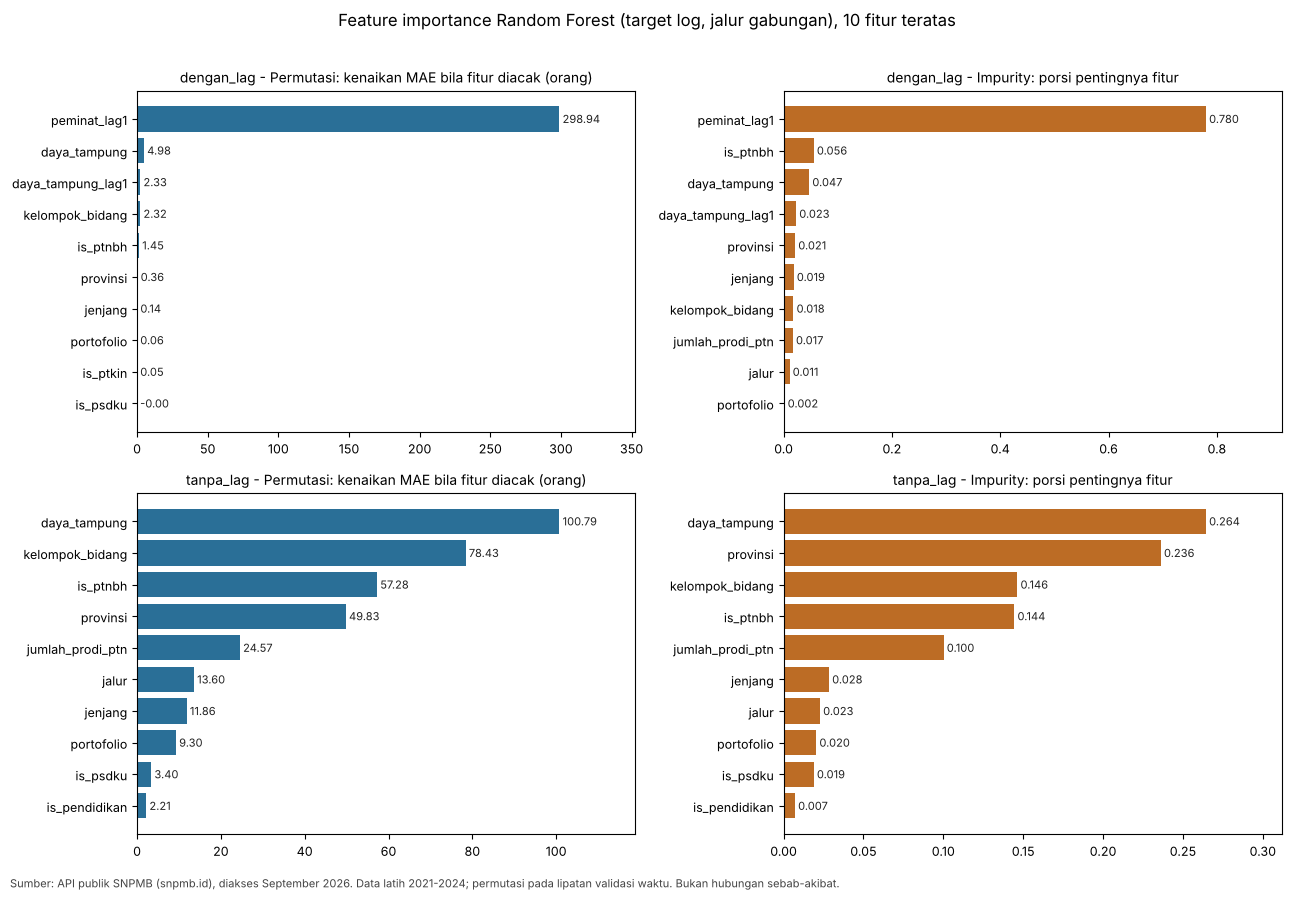

,skenario,target,jenis,peringkat,fitur,nilai
0,dengan_lag,asli,impurity,1,peminat_lag1,0.731
1,dengan_lag,asli,impurity,2,jenjang,0.048
2,dengan_lag,asli,impurity,3,daya_tampung,0.043
3,dengan_lag,asli,impurity,4,is_ptnbh,0.037
4,dengan_lag,asli,impurity,5,daya_tampung_lag1,0.034
5,dengan_lag,asli,permutasi,1,peminat_lag1,307.554
6,dengan_lag,asli,permutasi,2,daya_tampung,3.899
7,dengan_lag,asli,permutasi,3,daya_tampung_lag1,3.170
8,dengan_lag,asli,permutasi,4,is_ptnbh,2.980
9,dengan_lag,asli,permutasi,5,kelompok_bidang,1.855


In [6]:
# Feature importance (data latih saja; data uji 2025 TIDAK dipakai)
import matplotlib.pyplot as plt
from fondasi import FITUR_NUMERIK, FITUR_BINER, FITUR_LAG, FITUR_KATEGORIK

BERKAS_IMPORTANCE = AKAR / "hasil" / "grafik" / "importance_random_forest_2021_2024.csv"
BERKAS_GAMBAR = BERKAS_IMPORTANCE.with_suffix(".png")
ULANG_IMPORTANCE = False    # True = hitung ulang (lama); False = pakai CSV tersimpan bila ada
N_ULANG_PERMUTASI = 3       # pengacakan per fitur per lipatan
TARGET_GRAFIK = "log"       # dipilih dari skor validasi tuning, bukan dari data uji


def grup_fitur(kolom):
    """Petakan kolom hasil one-hot ke fitur asalnya (provinsi_Aceh -> provinsi)."""
    if kolom in FITUR_NUMERIK + FITUR_BINER + FITUR_LAG:
        return kolom
    for k in FITUR_KATEGORIK:
        if kolom.startswith(k + "_"):
            return k
    raise ValueError(f"Kolom {kolom!r} tidak terpetakan ke fitur asal")


def _latih(X, y, target):
    m = buat_model()    # pengaturan terpilih (PARAMETER_RF), 300 pohon
    m.fit(X, y if target == "asli" else ke_log(y))
    return m


def _prediksi(m, X, target):
    p = m.predict(X)
    return p if target == "asli" else dari_log(p)


if BERKAS_IMPORTANCE.exists() and not ULANG_IMPORTANCE:
    imp_tabel = pd.read_csv(BERKAS_IMPORTANCE)
    print(f"Memakai hasil tersimpan: {BERKAS_IMPORTANCE.name} ({len(imp_tabel)} baris)")
else:
    baris, mulai = [], time.time()
    for skenario in SKENARIO:
        X_tr, _, y_tr, _ = DATA[(skenario, None)]        # X_uji/y_uji sengaja diabaikan
        peta = pd.Series({c: grup_fitur(c) for c in X_tr.columns})
        daftar = list(dict.fromkeys(peta.values))
        for target in ("asli", "log"):
            # 1) impurity: model pada seluruh data latih, dijumlahkan per fitur asal
            m = _latih(X_tr, y_tr, target)
            imp = pd.Series(m.feature_importances_, index=X_tr.columns).groupby(peta).sum()
            assert abs(imp.sum() - 1) < 1e-6, "impurity importance harus berjumlah 1"
            for g in daftar:
                baris.append({"skenario": skenario, "target": target, "jenis": "impurity",
                              "fitur": g, "nilai": float(imp[g]), "simpangan_antar_lipatan": np.nan})
            # 2) permutasi pada lipatan validasi waktu
            naik_per_lipatan = {g: [] for g in daftar}
            for idx_latih, idx_val in lipatan_waktu(X_tr):
                m = _latih(X_tr.iloc[idx_latih], y_tr.iloc[idx_latih], target)
                Xv, yv = X_tr.iloc[idx_val], y_tr.iloc[idx_val].to_numpy()
                mae0 = np.mean(np.abs(yv - _prediksi(m, Xv, target)))
                for g in daftar:
                    kolom_g = list(peta.index[peta == g])
                    naik = []
                    for r in range(N_ULANG_PERMUTASI):
                        rng = np.random.default_rng(RANDOM_STATE + r)
                        Xp = Xv.copy()
                        Xp[kolom_g] = Xv[kolom_g].to_numpy()[rng.permutation(len(Xv))]
                        naik.append(np.mean(np.abs(yv - _prediksi(m, Xp, target))) - mae0)
                    naik_per_lipatan[g].append(float(np.mean(naik)))
            for g in daftar:
                baris.append({"skenario": skenario, "target": target, "jenis": "permutasi",
                              "fitur": g, "nilai": float(np.mean(naik_per_lipatan[g])),
                              "simpangan_antar_lipatan": float(np.std(naik_per_lipatan[g]))})
            print(f"{skenario} | target={target} selesai ({time.time() - mulai:.0f} dtk)", flush=True)
    imp_tabel = pd.DataFrame(baris)
    imp_tabel["peringkat"] = (imp_tabel.groupby(["skenario", "target", "jenis"])["nilai"]
                              .rank(ascending=False, method="min").astype(int))
    BERKAS_IMPORTANCE.parent.mkdir(parents=True, exist_ok=True)
    imp_tabel.to_csv(BERKAS_IMPORTANCE, index=False, encoding="utf-8-sig")

# Grafik utama: target log; baris = skenario, kolom = jenis ukuran
WARNA = {"permutasi": "#2a6f97", "impurity": "#bc6c25"}
JUDUL = {"permutasi": "Permutasi: kenaikan MAE bila fitur diacak (orang)",
         "impurity": "Impurity: porsi pentingnya fitur"}
fig, sumbu = plt.subplots(len(SKENARIO), 2, figsize=(13, 9))
for i, skenario in enumerate(SKENARIO):
    for j, jenis in enumerate(("permutasi", "impurity")):
        d = (imp_tabel[(imp_tabel.skenario == skenario) & (imp_tabel.target == TARGET_GRAFIK)
                       & (imp_tabel.jenis == jenis)].sort_values("nilai", ascending=False).head(10))
        d = d.iloc[::-1]
        ax = sumbu[i, j]
        ax.barh(d["fitur"], d["nilai"], color=WARNA[jenis])
        for y_pos, v in enumerate(d["nilai"]):
            ax.text(v, y_pos, f" {v:.2f}" if jenis == "permutasi" else f" {v:.3f}",
                    va="center", fontsize=8, color="#222222")
        ax.set_xlim(0, d["nilai"].max() * 1.18)      # sumbu nilai dimulai dari nol
        ax.set_title(f"{skenario} - {JUDUL[jenis]}", fontsize=10)
        ax.tick_params(labelsize=9)
fig.suptitle("Feature importance Random Forest (target log, jalur gabungan), 10 fitur teratas", fontsize=12)
fig.text(0.01, 0.005, "Sumber: API publik SNPMB (snpmb.id), diakses September 2026. Data latih 2021-2024; "
         "permutasi pada lipatan validasi waktu. Bukan hubungan sebab-akibat.", fontsize=8, color="#444444")
fig.tight_layout(rect=(0, 0.02, 1, 0.97))
BERKAS_GAMBAR.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(BERKAS_GAMBAR, dpi=300, bbox_inches="tight")
plt.show()

# Tabel ringkas 5 teratas per kombinasi
ringkas = (imp_tabel[imp_tabel["peringkat"] <= 5]
           .sort_values(["skenario", "target", "jenis", "peringkat"])
           [["skenario", "target", "jenis", "peringkat", "fitur", "nilai"]])
display(ringkas.round(3).reset_index(drop=True))

### Cara membaca dan keterbatasan

- **Impurity bisa bias.** Ukuran ini cenderung menaikkan fitur numerik dengan banyak kemungkinan pemisahan (misalnya `daya_tampung`, `peminat_lag1`) dan menurunkan fitur kategorik dengan sedikit level. Karena itu permutasi disajikan sebagai pembanding yang lebih mudah dipertanggungjawabkan.
- **Fitur yang saling berkorelasi berbagi informasi.** `daya_tampung` dengan `daya_tampung_lag1`, atau `peminat_lag1` dengan ukuran PTN, dapat membuat nilai satu fitur tampak kecil karena fitur lain menggantikan perannya saat diacak.
- **Permutasi memakai 2 lipatan (`dengan_lag`) atau 3 lipatan (`tanpa_lag`)** dan 3 kali pengacakan per fitur, sehingga angkanya berisik. Kolom `simpangan_antar_lipatan` di CSV menunjukkan sebarannya; selisih kecil antarfitur jangan ditafsirkan sebagai perbedaan nyata.
- **Pada `dengan_lag`, fitur lag mencerminkan riwayat peminat prodi itu sendiri**, bukan sifat prodi. Perbandingan antara dua skenario menunjukkan seberapa besar model bersandar pada riwayat, bukan penyebab naik-turunnya peminat.
- **Importance bukan bukti sebab-akibat.** Ia hanya menunjukkan fitur mana yang paling dipakai model untuk menebak peminat pada data ini.
- Hasil berlaku untuk model jalur gabungan dengan pengaturan terpilih; belum diperiksa per jalur atau per kelompok bidang.